1. Crosstab Analysis:

- Create a crosstab between the product category and the isBestSeller status.

- Are there categories where being a best-seller is more prevalent?

Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.

In [5]:
!pip install researchpy
!pip install scipy

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import researchpy as rp
import scipy.stats as stats

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [ ]:
# Part 1
# 1.
# Crosstab between category and bestseller
crosstab = pd.crosstab(df['category'], df['isBestSeller'])

# Bestsellers in each category
crosstab_prop = crosstab.div(crosstab.sum(axis=1), axis=0)
crosstab_prop['BestSeller_Proportion'] = crosstab_prop[True]
crosstab_prop.sort_values('BestSeller_Proportion', ascending=False)

isBestSeller,False,True,BestSeller_Proportion
category,,,
Grocery,0.941865,0.058135,0.058135
Smart Home Security & Lighting,0.942308,0.057692,0.057692
Health & Personal Care,0.942314,0.057686,0.057686
Mobile Phone Accessories,0.957529,0.042471,0.042471
Power & Hand Tools,0.964661,0.035339,0.035339
...,...,...,...
"CD, Disc & Tape Players",1.000000,0.000000,0.000000
General Music-Making Accessories,1.000000,0.000000,0.000000
Snowboard Boots,1.000000,0.000000,0.000000


In [ ]:
# 2. Chi-square test
chi2, p, dof, expected = chi2_contingency(crosstab)
print(f"Chi2 = {chi2}, p-value = {p}")

Chi2 = 36540.20270061387, p-value = 0.0


In [17]:
# 2.
n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape)-1)))
print(f"Cramér's V = {cramers_v}")

Cramér's V = 0.1222829439760564


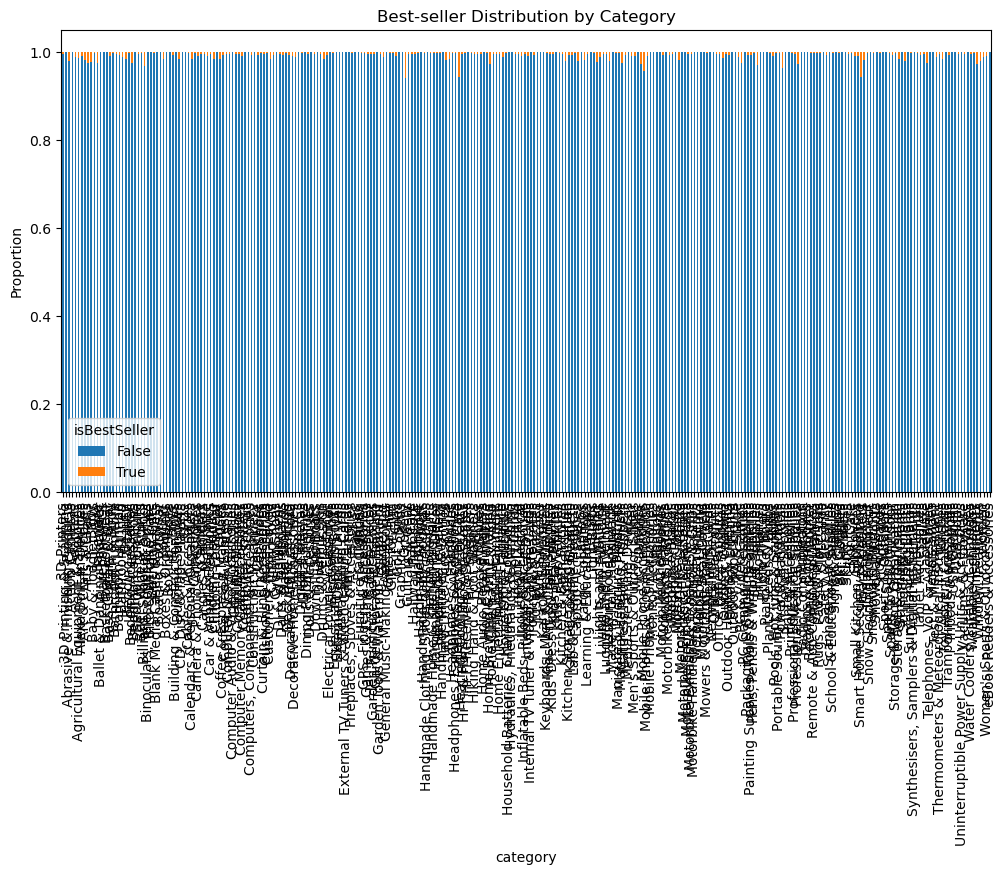

In [20]:
# 4.
crosstab_prop[[0,1]].plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Best-seller Distribution by Category")
plt.ylabel("Proportion")
plt.show()


In [21]:
# Part 2
# 0.
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower) & (df['price'] <= upper)]

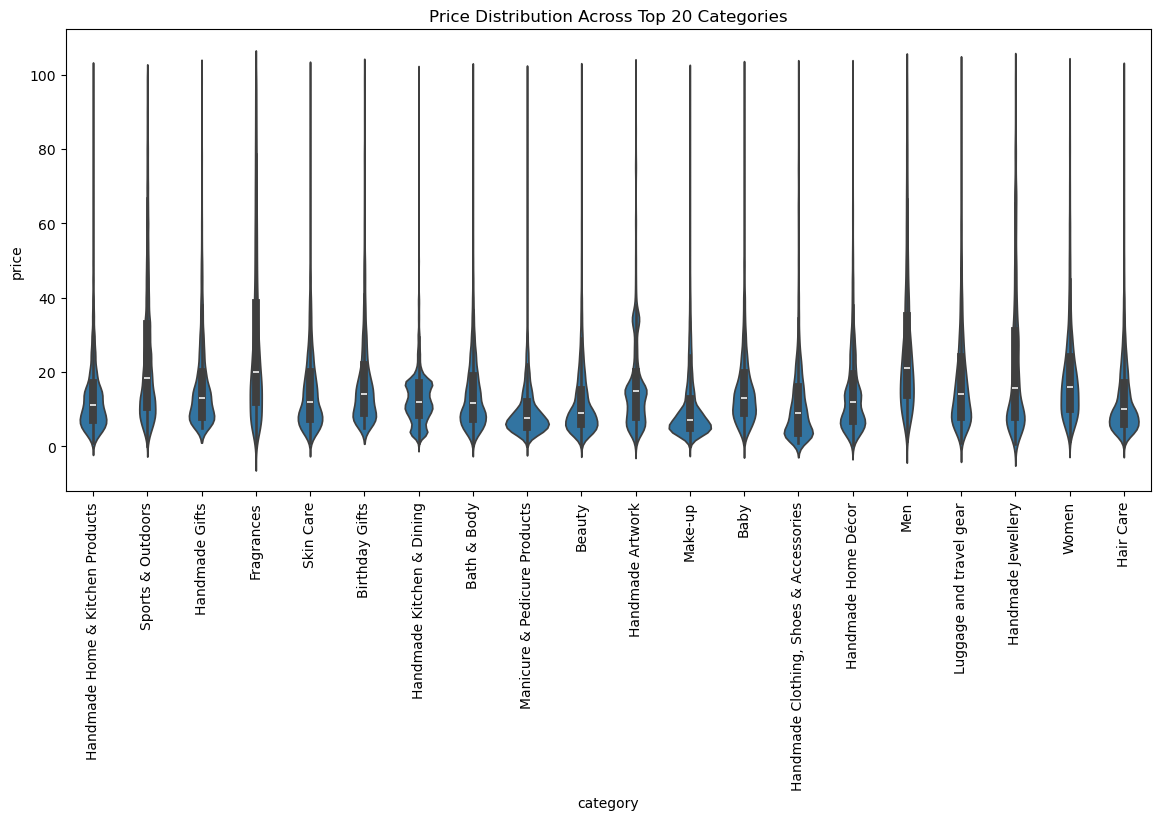

In [22]:
# 1.
top20_categories = df_no_outliers['category'].value_counts().nlargest(20).index

plt.figure(figsize=(14,6))
sns.violinplot(data=df_no_outliers[df_no_outliers['category'].isin(top20_categories)], 
               x='category', y='price')
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Categories")
plt.show()

Perfumes for men tend to have the highest median price

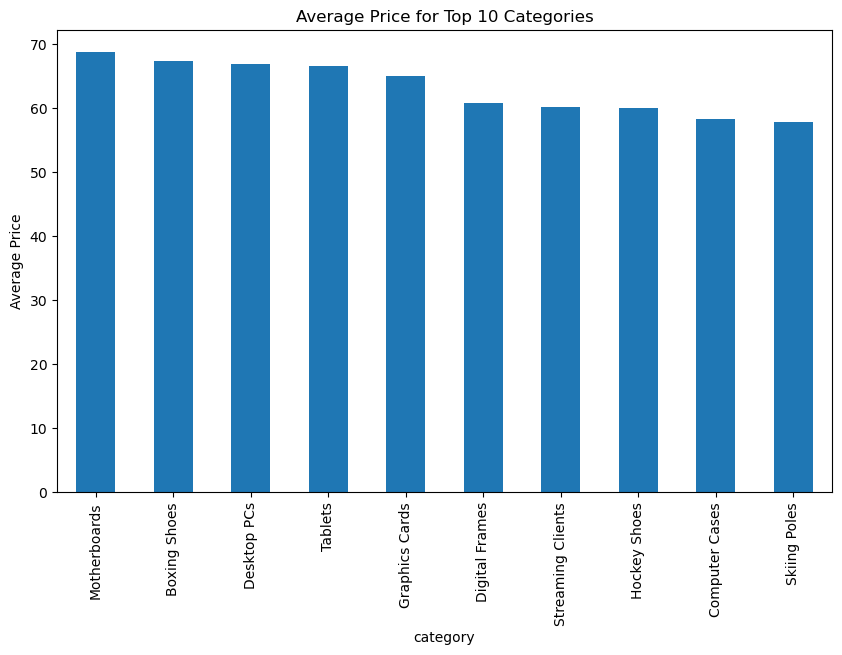

In [25]:
# 2.
avg_price = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)

avg_price.head(10).plot(kind="bar", figsize=(10,6))
plt.title("Average Price for Top 10 Categories")
plt.ylabel("Average Price")
plt.show()

Motherboards tend to have the highest avergae price

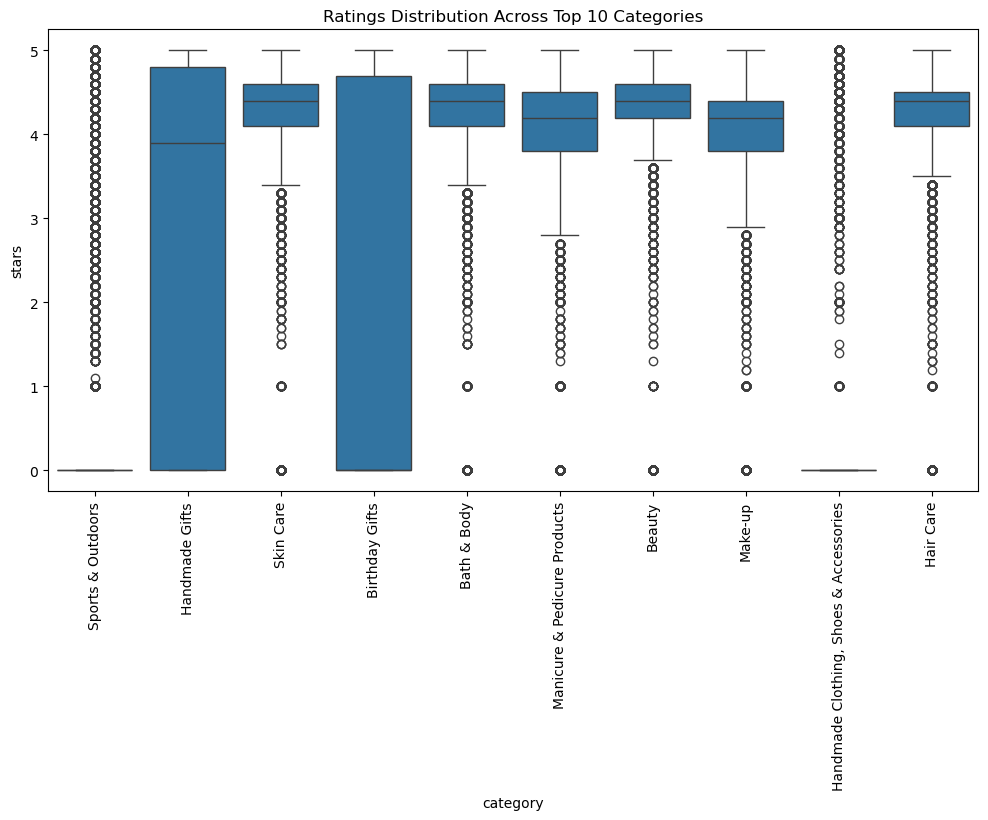

In [24]:
# 3.
top10_categories = df_no_outliers['category'].value_counts().nlargest(10).index

plt.figure(figsize=(12,6))
sns.boxplot(data=df_no_outliers[df_no_outliers['category'].isin(top10_categories)],
            x='category', y='stars')
plt.xticks(rotation=90)
plt.title("Ratings Distribution Across Top 10 Categories")
plt.show()

Sports & Outdoors category tend to receive the highest median rating

In [26]:
# Part 3
# 1.
correlation = df_no_outliers[['price','stars']].corr()
print(correlation)

          price     stars
price  1.000000 -0.077673
stars -0.077673  1.000000


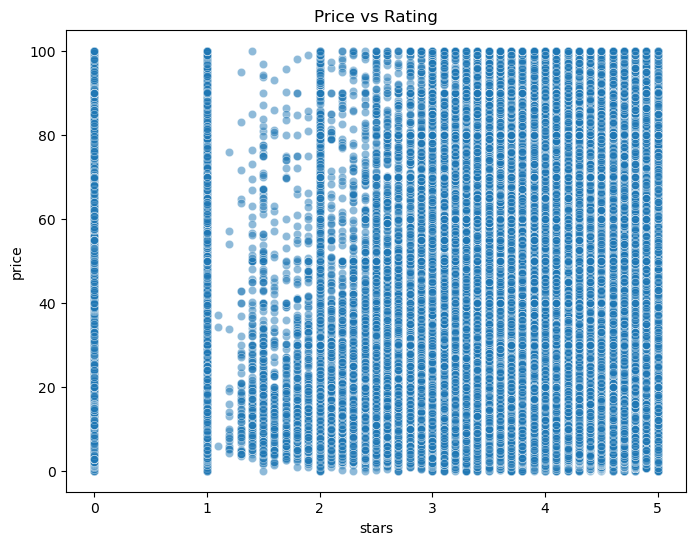

In [27]:
# 2.
# Scatter Plot
plt.figure(figsize=(8,6))
sns.scatterplot(x='stars', y='price', data=df_no_outliers, alpha=0.5)
plt.title("Price vs Rating")
plt.show()

Higher prices tend to have more ratings

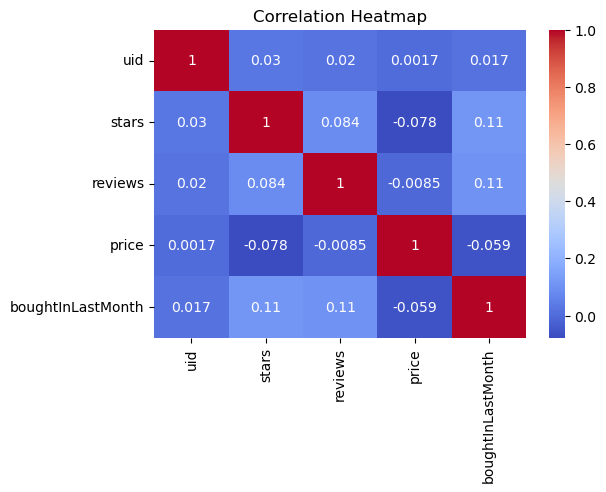

In [32]:
# Heatmap
plt.figure(figsize=(6,4))
numeric_cols = df_no_outliers.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

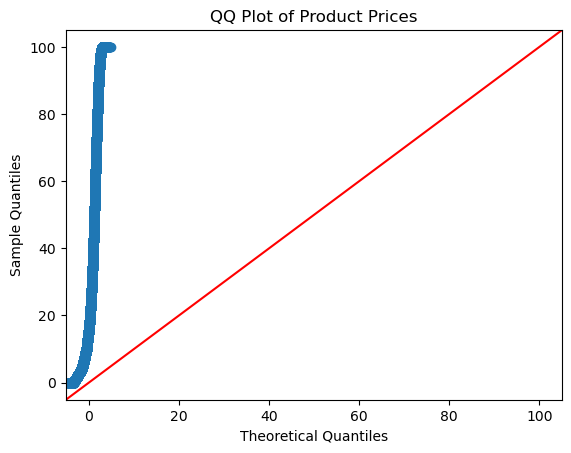

In [30]:
# QQ Plot
import statsmodels.api as sm
sm.qqplot(df_no_outliers['price'], line ='45')
plt.title("QQ Plot of Product Prices")
plt.show()